# BTL02 – TV4: Trực quan hóa Filter, E4 Pretrained, Đa seed & Phân tích

**Thành viên:** Lê Thị Thanh Tuyền – 3123411332  
**Vai trò:** Trực quan hóa filter, fine-tune pretrained (E4), chạy mô hình tốt nhất với nhiều seed, phân tích & tổng hợp  
**Môn:** Học sâu – DCT123C4 – Nhóm 07-09  
**Ngày chạy:** 24/11/2026

---

> **Yêu cầu Kaggle:**
> - **GPU T4** (hoặc GPU khả dụng khác) – bật trong Settings → Accelerator
> - **Internet ON** – để tải pretrained weights từ torchvision  
> - **FER2013 CSV** – Add Input dataset chứa `fer2013.csv`

## Bước 0: Kiểm tra môi trường GPU & Clone repo

In [1]:
!nvidia-smi
from datetime import datetime, timezone, timedelta
LOCAL_TZ = timezone(timedelta(hours=7), name="UTC+07")
print("Local time (UTC+7):", datetime.now(LOCAL_TZ).isoformat(timespec="seconds"))
print("Note: nvidia-smi above shows the Kaggle host clock in UTC.")
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Mon Nov 23 20:28:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!git clone https://github.com/Truongbuiii/SGU26K2_HocSau_S5_DCT123C4_0709_Nhom.git /kaggle/working/repo
%cd /kaggle/working/repo/Tuan11

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 677, done.
remote: Counting objects: 100% (475/475), done.
remote: Compressing objects: 100% (381/381), done.
remote: Total 677 (delta 175), reused 315 (delta 84), pack-reused 202 (from 1)
Receiving objects: 100% (677/677), 62.26 MiB | 36.77 MiB/s, done.
Resolving deltas: 100% (209/209), done.
/kaggle/working/repo/Tuan11


## Bước 1: Xác định đường dẫn FER2013 CSV & Kiểm tra dữ liệu

In [3]:
import os
import glob

# Tìm file fer2013.csv trong /kaggle/input
found = glob.glob('/kaggle/input/**/fer2013.csv', recursive=True)
print("Các file fer2013.csv tìm thấy:")
for f in found:
    print(f"  {f}  ({os.path.getsize(f) / 1e6:.1f} MB)")

# Chọn file đầu tiên tìm được
CSV = found[0] if found else None
print(f"\n=> Sử dụng: {CSV}")
assert CSV is not None, "Chưa tìm thấy fer2013.csv! Hãy Add Input dataset."

# Đặt biến môi trường để các script src/ sử dụng
os.environ['FER2013_CSV'] = CSV

Các file fer2013.csv tìm thấy:
  /kaggle/input/datasets/deadskull7/fer2013/fer2013.csv  (301.1 MB)

=> Sử dụng: /kaggle/input/datasets/deadskull7/fer2013/fer2013.csv


In [4]:
# Kiểm tra dữ liệu: phải đạt 28709 / 3589 / 3589
!python src/dataset.py

=== KIỂM TRA DỮ LIỆU src/dataset.py ===
Số lượng ảnh từng tập:
  train :  28709 ảnh (chuẩn 28709) -> OK
  valid :   3589 ảnh (chuẩn 3589) -> OK
  test  :   3589 ảnh (chuẩn 3589) -> OK
Phân bố lớp trong tập train:
  0 Angry    :  3995
  1 Disgust  :   436
  2 Fear     :  4097
  3 Happy    :  7215
  4 Sad      :  4830
  5 Surprise :  3171
  6 Neutral  :  4965
Một batch train: x=(64, 1, 48, 48) torch.float32, y=(64,) torch.int64
Giá trị x trong [0.00, 1.00]
Class weights: [1.027, 9.407, 1.001, 0.568, 0.849, 1.293, 0.826]
=== KẾT QUẢ: ĐẠT (đủ 28709/3589/3589) ===


## Bước 2: Cài đặt thư viện còn thiếu (nếu cần)

In [5]:
# Cài scikit-learn nếu chưa có (cần cho evaluate)
try:
    import sklearn
    print(f"scikit-learn đã có: {sklearn.__version__}")
except ImportError:
    !pip install -q scikit-learn
    import sklearn
    print(f"Đã cài scikit-learn: {sklearn.__version__}")

try:
    import matplotlib
    print(f"matplotlib đã có: {matplotlib.__version__}")
except ImportError:
    !pip install -q matplotlib

scikit-learn đã có: 1.6.1
matplotlib đã có: 3.10.0


---
## Phần A: E4-01 – Fine-tune ResNet18 (ImageNet pretrained)

Fine-tune ResNet18 pretrained trên ImageNet. Pipeline:
- FER2013 grayscale 48×48 → replicate 3 kênh RGB → resize 96×96 → normalize ImageNet mean/std
- Thay lớp FC cuối → 7 lớp cảm xúc
- AdamW, lr=1e-4, 30 epochs, patience=7, AMP trên GPU

In [6]:
!python src/train_pretrained.py \
    --arch resnet18 \
    --seed 42 \
    --csv_path "$FER2013_CSV" \
    --output_root /kaggle/working/results/runs

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|███████████████████████████████████████| 44.7M/44.7M [00:00<00:00, 180MB/s]
epoch 01 train_loss=1.3387 train_acc=0.4900 val_loss=1.1382 val_acc=0.5726
epoch 02 train_loss=1.0874 train_acc=0.5867 val_loss=1.0562 val_acc=0.6043
epoch 03 train_loss=0.9990 train_acc=0.6238 val_loss=0.9927 val_acc=0.6436
epoch 04 train_loss=0.9389 train_acc=0.6489 val_loss=0.9858 val_acc=0.6478
epoch 05 train_loss=0.8898 train_acc=0.6664 val_loss=0.9580 val_acc=0.6495
epoch 06 train_loss=0.8478 train_acc=0.6839 val_loss=0.9696 val_acc=0.6601
epoch 07 train_loss=0.8091 train_acc=0.6999 val_loss=0.9412 val_acc=0.6590
epoch 08 train_loss=0.7712 train_acc=0.7141 val_loss=0.9526 val_acc=0.6606
epoch 09 train_loss=0.7306 train_acc=0.7277 val_loss=1.0021 val_acc=0.6629
epoch 10 train_loss=0.6912 train_acc=0.7448 val_loss=1.0342 val_acc=0.6701
epoch 11 train_loss=0.6574 train_acc

In [7]:
# Kiểm tra kết quả E4-01
import json
from pathlib import Path

run_e4_resnet = Path('/kaggle/working/results/runs/E4-resnet18_resnet18_s42')
if (run_e4_resnet / 'best_metrics.json').exists():
    metrics = json.loads((run_e4_resnet / 'best_metrics.json').read_text())
    print(f"E4-01 ResNet18 - Best epoch: {metrics['epoch']}, Val loss: {metrics['val_loss']:.4f}, Val acc: {metrics['val_acc']:.4f}")
else:
    print("Chưa có best_metrics.json!")

# Kiểm tra best.pt tồn tại
print(f"best.pt exists: {(run_e4_resnet / 'best.pt').exists()}")
print(f"Files: {[f.name for f in run_e4_resnet.iterdir()]}")

E4-01 ResNet18 - Best epoch: 7, Val loss: 0.9412, Val acc: 0.6590
best.pt exists: True
Files: ['config.json', 'env.json', 'history.csv', 'best_metrics.json', 'best.pt']


## Phần B: E4-02 – Fine-tune VGG16 (ImageNet pretrained)

Cùng pipeline như ResNet18, nhưng VGG16 nặng hơn nhiều (138M params). Thời gian chạy lâu hơn.

In [8]:
!python src/train_pretrained.py \
    --arch vgg16 \
    --seed 42 \
    --csv_path "$FER2013_CSV" \
    --output_root /kaggle/working/results/runs

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|█████████████████████████████████████████| 528M/528M [00:02<00:00, 248MB/s]
epoch 01 train_loss=1.3306 train_acc=0.4887 val_loss=1.1446 val_acc=0.5687
epoch 02 train_loss=1.0999 train_acc=0.5849 val_loss=1.0738 val_acc=0.5940
epoch 03 train_loss=1.0091 train_acc=0.6213 val_loss=1.0073 val_acc=0.6199
epoch 04 train_loss=0.9456 train_acc=0.6477 val_loss=0.9477 val_acc=0.6581
epoch 05 train_loss=0.9021 train_acc=0.6643 val_loss=0.9531 val_acc=0.6428
epoch 06 train_loss=0.8578 train_acc=0.6795 val_loss=0.9624 val_acc=0.6498
epoch 07 train_loss=0.8229 train_acc=0.6933 val_loss=0.9390 val_acc=0.6581
epoch 08 train_loss=0.7782 train_acc=0.7112 val_loss=0.9275 val_acc=0.6665
epoch 09 train_loss=0.7519 train_acc=0.7211 val_loss=0.9350 val_acc=0.6640
epoch 10 train_loss=0.7175 train_acc=0.7325 val_loss=0.9482 val_acc=0.6723
epoch 11 train_loss=0.6817 train_acc=0.747

In [9]:
# Kiểm tra kết quả E4-02
run_e4_vgg = Path('/kaggle/working/results/runs/E4-vgg16_vgg16_s42')
if (run_e4_vgg / 'best_metrics.json').exists():
    metrics = json.loads((run_e4_vgg / 'best_metrics.json').read_text())
    print(f"E4-02 VGG16 - Best epoch: {metrics['epoch']}, Val loss: {metrics['val_loss']:.4f}, Val acc: {metrics['val_acc']:.4f}")
else:
    print("Chưa có best_metrics.json!")

print(f"best.pt exists: {(run_e4_vgg / 'best.pt').exists()}")

E4-02 VGG16 - Best epoch: 11, Val loss: 0.9233, Val acc: 0.6826
best.pt exists: True


## So sánh E4-01 (ResNet18) vs E4-02 (VGG16)

In [10]:
import pandas as pd

rows = []
for label, run_dir in [('E4-01 ResNet18', run_e4_resnet), ('E4-02 VGG16', run_e4_vgg)]:
    bm = run_dir / 'best_metrics.json'
    env = run_dir / 'env.json'
    if bm.exists():
        m = json.loads(bm.read_text())
        e = json.loads(env.read_text()) if env.exists() else {}
        rows.append({
            'Run': label,
            'Best Epoch': m['epoch'],
            'Val Loss': f"{m['val_loss']:.4f}",
            'Val Acc (%)': f"{m['val_acc']*100:.2f}" if m['val_acc'] < 1 else f"{m['val_acc']:.2f}",
            'Time (s)': f"{e.get('seconds', 'N/A')}",
            'GPU': e.get('gpu', 'N/A')
        })

df_e4 = pd.DataFrame(rows)
print("\n=== So sánh E4 Transfer Learning ===")
print(df_e4.to_string(index=False))


=== So sánh E4 Transfer Learning ===
           Run  Best Epoch Val Loss Val Acc (%)           Time (s)      GPU
E4-01 ResNet18           7   0.9412       65.90 187.27427101135254 Tesla T4
   E4-02 VGG16          11   0.9233       68.26 1317.5890471935272 Tesla T4


---
## Phần C: E4-03 – Chạy cấu hình CNN tốt nhất với 3 seed (42, 43, 44)

Theo `results/summary.csv`, cấu hình tốt nhất từ E1–E3 là **E2-04**:  
Medium, ReLU, không BN, conv_dropout=0.2, fc_dropout=0.5, `flip_affine`, `div255`, Adam lr=1e-4, batch 64, 100 epochs, patience 10.

Chạy 3 seed để đo độ ổn định (mean ± std).

In [11]:
# Seed 42
!FER2013_CSV="$FER2013_CSV" python src/train.py \
    --exp_id E4-03 \
    --exp_name best_seed42 \
    --runner TV4 \
    --arch medium \
    --activation relu \
    --conv_dropout 0.2 \
    --fc_dropout 0.5 \
    --optimizer adam \
    --lr 1e-4 \
    --batch_size 64 \
    --aug_name flip_affine \
    --norm div255 \
    --epochs 100 \
    --patience 10 \
    --seed 42

Run: E4-03 | Name: best_seed42 | Seed: 42 | Runner: TV4
Arch: medium | Act: relu | BN: False | ConvDrop: 0.2 | Params: 11,327,303
Optimizer: adam (lr=0.0001, wd=0.0) | Scheduler: none | Batch: 64 | Device: cuda (Tesla T4)
Epoch 001/100 | train_loss: 1.8431 | train_acc: 0.2429 | val_loss: 1.8237 | val_acc: 0.2491 | lr: 1.00e-04 | time: 20.40s  [*BEST*]
Epoch 002/100 | train_loss: 1.7842 | train_acc: 0.2678 | val_loss: 1.6931 | val_acc: 0.3377 | lr: 1.00e-04 | time: 20.28s  [*BEST*]
Epoch 003/100 | train_loss: 1.6709 | train_acc: 0.3424 | val_loss: 1.4953 | val_acc: 0.4174 | lr: 1.00e-04 | time: 20.05s  [*BEST*]
Epoch 004/100 | train_loss: 1.5438 | train_acc: 0.4055 | val_loss: 1.4089 | val_acc: 0.4575 | lr: 1.00e-04 | time: 19.68s  [*BEST*]
Epoch 005/100 | train_loss: 1.4412 | train_acc: 0.4450 | val_loss: 1.3162 | val_acc: 0.4976 | lr: 1.00e-04 | time: 19.67s  [*BEST*]
Epoch 006/100 | train_loss: 1.3636 | train_acc: 0.4767 | val_loss: 1.2473 | val_acc: 0.5235 | lr: 1.00e-04 | time: 19.

In [12]:
# Seed 43
!FER2013_CSV="$FER2013_CSV" python src/train.py \
    --exp_id E4-03 \
    --exp_name best_seed43 \
    --runner TV4 \
    --arch medium \
    --activation relu \
    --conv_dropout 0.2 \
    --fc_dropout 0.5 \
    --optimizer adam \
    --lr 1e-4 \
    --batch_size 64 \
    --aug_name flip_affine \
    --norm div255 \
    --epochs 100 \
    --patience 10 \
    --seed 43

Run: E4-03 | Name: best_seed43 | Seed: 43 | Runner: TV4
Arch: medium | Act: relu | BN: False | ConvDrop: 0.2 | Params: 11,327,303
Optimizer: adam (lr=0.0001, wd=0.0) | Scheduler: none | Batch: 64 | Device: cuda (Tesla T4)
Epoch 001/100 | train_loss: 1.8625 | train_acc: 0.2415 | val_loss: 1.8238 | val_acc: 0.2502 | lr: 1.00e-04 | time: 20.29s  [*BEST*]
Epoch 002/100 | train_loss: 1.7674 | train_acc: 0.2795 | val_loss: 1.6985 | val_acc: 0.3385 | lr: 1.00e-04 | time: 20.27s  [*BEST*]
Epoch 003/100 | train_loss: 1.6517 | train_acc: 0.3510 | val_loss: 1.5111 | val_acc: 0.4174 | lr: 1.00e-04 | time: 20.01s  [*BEST*]
Epoch 004/100 | train_loss: 1.5499 | train_acc: 0.4011 | val_loss: 1.4049 | val_acc: 0.4625 | lr: 1.00e-04 | time: 19.66s  [*BEST*]
Epoch 005/100 | train_loss: 1.4669 | train_acc: 0.4382 | val_loss: 1.3383 | val_acc: 0.4890 | lr: 1.00e-04 | time: 19.61s  [*BEST*]
Epoch 006/100 | train_loss: 1.3861 | train_acc: 0.4700 | val_loss: 1.2907 | val_acc: 0.5052 | lr: 1.00e-04 | time: 19.

In [13]:
# Seed 44
!FER2013_CSV="$FER2013_CSV" python src/train.py \
    --exp_id E4-03 \
    --exp_name best_seed44 \
    --runner TV4 \
    --arch medium \
    --activation relu \
    --conv_dropout 0.2 \
    --fc_dropout 0.5 \
    --optimizer adam \
    --lr 1e-4 \
    --batch_size 64 \
    --aug_name flip_affine \
    --norm div255 \
    --epochs 100 \
    --patience 10 \
    --seed 44

Run: E4-03 | Name: best_seed44 | Seed: 44 | Runner: TV4
Arch: medium | Act: relu | BN: False | ConvDrop: 0.2 | Params: 11,327,303
Optimizer: adam (lr=0.0001, wd=0.0) | Scheduler: none | Batch: 64 | Device: cuda (Tesla T4)
Epoch 001/100 | train_loss: 1.8563 | train_acc: 0.2408 | val_loss: 1.8200 | val_acc: 0.2541 | lr: 1.00e-04 | time: 20.32s  [*BEST*]
Epoch 002/100 | train_loss: 1.7803 | train_acc: 0.2729 | val_loss: 1.6717 | val_acc: 0.3736 | lr: 1.00e-04 | time: 20.25s  [*BEST*]
Epoch 003/100 | train_loss: 1.6569 | train_acc: 0.3501 | val_loss: 1.4903 | val_acc: 0.4335 | lr: 1.00e-04 | time: 19.99s  [*BEST*]
Epoch 004/100 | train_loss: 1.5395 | train_acc: 0.4025 | val_loss: 1.3858 | val_acc: 0.4778 | lr: 1.00e-04 | time: 19.68s  [*BEST*]
Epoch 005/100 | train_loss: 1.4475 | train_acc: 0.4427 | val_loss: 1.3174 | val_acc: 0.4946 | lr: 1.00e-04 | time: 19.69s  [*BEST*]
Epoch 006/100 | train_loss: 1.3724 | train_acc: 0.4742 | val_loss: 1.2677 | val_acc: 0.5082 | lr: 1.00e-04 | time: 19.

### Tổng hợp kết quả 3 seed (Mean ± Std)

In [14]:
# Tổng hợp bằng summarize_tv4.py
!python src/summarize_tv4.py \
    --run_dirs results/runs/E4-03_best_seed42_s42 results/runs/E4-03_best_seed43_s43 results/runs/E4-03_best_seed44_s44 \
    --out results/summary_TV4_seeds.csv

Saved seed summary: /kaggle/working/repo/Tuan11/results/summary_TV4_seeds.csv


In [15]:
# Hiển thị bảng tổng hợp
import pandas as pd

summary_path = Path('results/summary_TV4_seeds.csv')
if summary_path.exists():
    df_seeds = pd.read_csv(summary_path)
    print("\n=== Kết quả 3 seed – Mô hình tốt nhất (E2-04 config) ===")
    print(df_seeds.to_string(index=False))
else:
    print("Chưa có file summary!")


=== Kết quả 3 seed – Mô hình tốt nhất (E2-04 config) ===
                  run exp_id  seed  best_epoch  train_acc        val_loss         val_acc
E4-03_best_seed42_s42  E4-03  42.0        43.0   0.689575        0.939398        0.663973
E4-03_best_seed43_s43  E4-03  43.0        57.0   0.715664        0.931446        0.668153
E4-03_best_seed44_s44  E4-03  44.0        43.0   0.690620        0.928837        0.664531
    MEAN ± SAMPLE STD    NaN   NaN         NaN        NaN 0.9332 ± 0.0055 0.6656 ± 0.0023


---
## Phần D: Trực quan hóa Filter & Feature Map

Dùng checkpoint CNN tốt nhất (seed 42) để:
1. Vẽ kernel lớp convolution đầu tiên
2. Vẽ feature map lớp convolution cuối (theo từng lớp cảm xúc)
3. Activation maximization cho một số filter cuối

In [16]:
!python src/visualize_filters.py \
    --run_dir results/runs/E4-03_best_seed42_s42 \
    --csv_path "$FER2013_CSV" \
    --out_dir results/figures

Saved visualizations to /kaggle/working/repo/Tuan11/results/figures



=== E4-03_best_seed42_s42_first_kernels.png ===


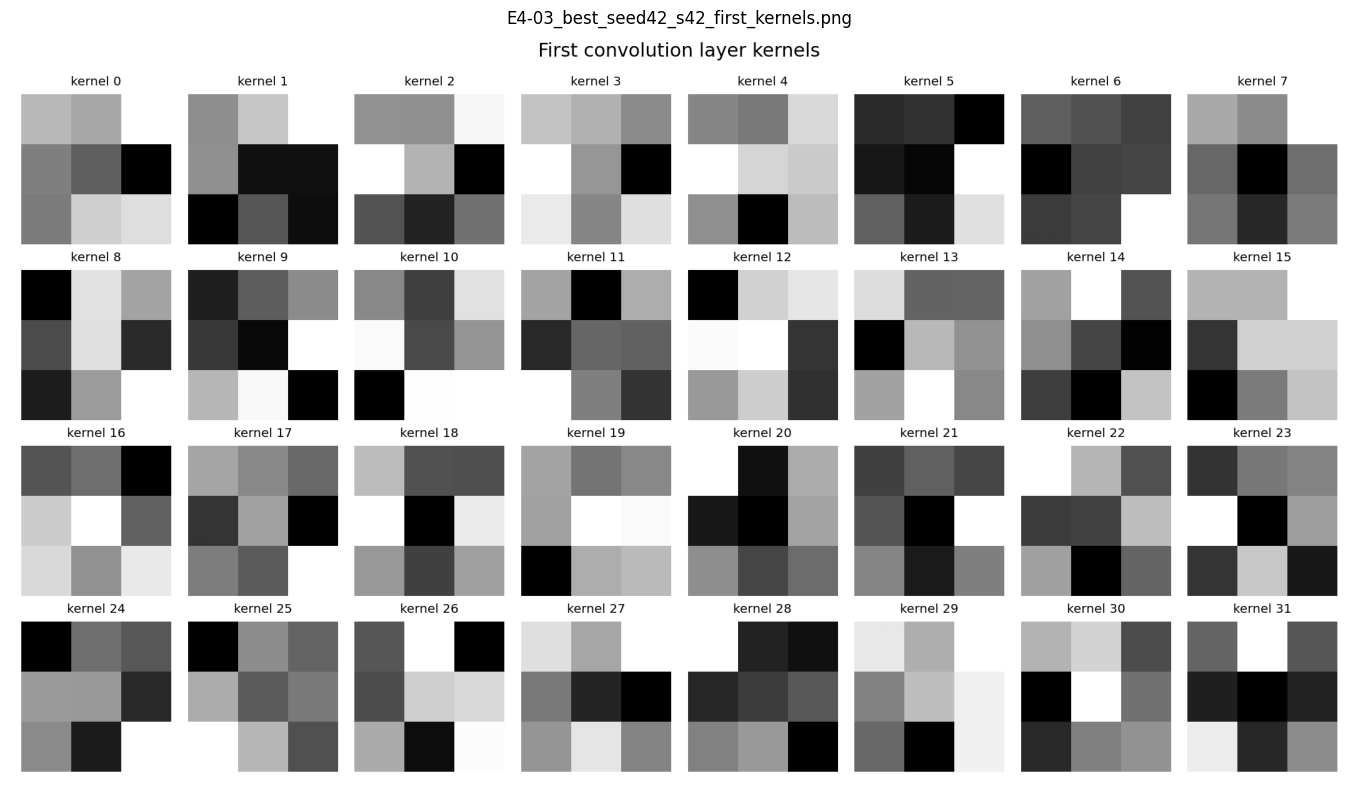


=== E4-03_best_seed42_s42_last_feature_maps.png ===


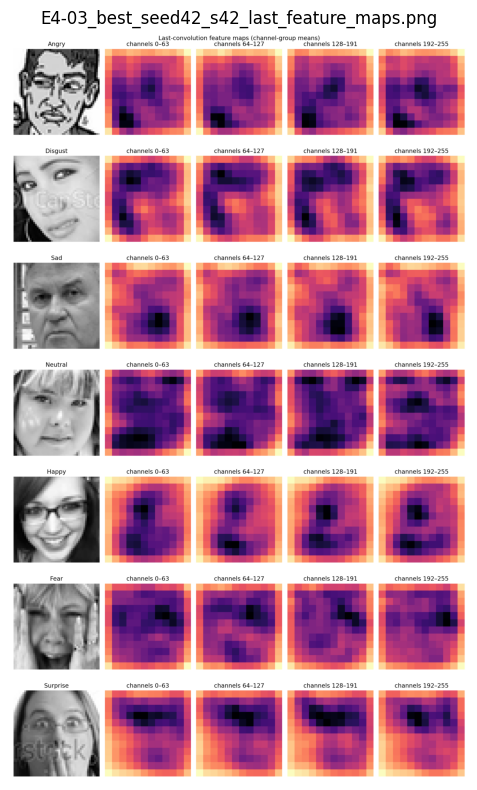


=== E4-03_best_seed42_s42_activation_maximization.png ===


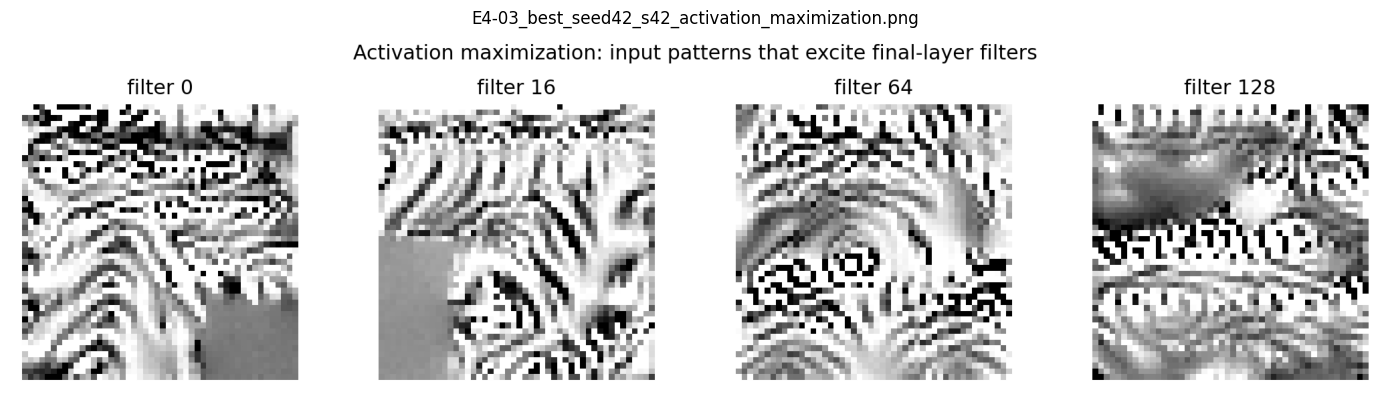

In [17]:
# Hiển thị các hình đã tạo
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig_dir = Path('results/figures')
tag = 'E4-03_best_seed42_s42'

for suffix in ['_first_kernels.png', '_last_feature_maps.png', '_activation_maximization.png']:
    fpath = fig_dir / f"{tag}{suffix}"
    if fpath.exists():
        print(f"\n=== {fpath.name} ===")
        img = mpimg.imread(str(fpath))
        fig, ax = plt.subplots(figsize=(14, 8))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(fpath.name)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Chưa có: {fpath}")

## Phần E: Grad-CAM (tùy chọn)

In [18]:
!python src/gradcam.py \
    --run_dir results/runs/E4-03_best_seed42_s42 \
    --csv_path "$FER2013_CSV" \
    --out results/figures/gradcam_final.png

Saved results/figures/gradcam_final.png


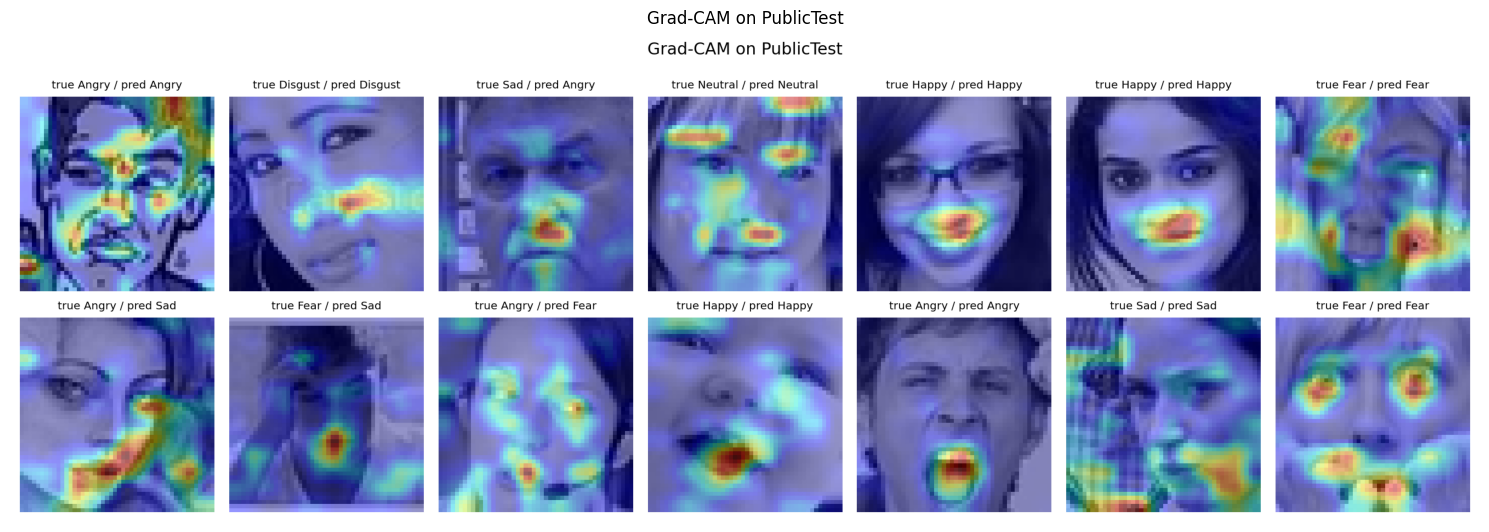

In [19]:
# Hiển thị Grad-CAM
gradcam_path = Path('results/figures/gradcam_final.png')
if gradcam_path.exists():
    img = mpimg.imread(str(gradcam_path))
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title('Grad-CAM on PublicTest')
    plt.tight_layout()
    plt.show()
else:
    print(f"Chưa có: {gradcam_path}")

---
## Phần F: Đánh giá PrivateTest (chỉ chạy sau khi khóa mô hình)

> **QUAN TRỌNG:** Chỉ đánh giá trên PrivateTest SAU KHI đã chốt cấu hình và checkpoint theo PublicTest (validation). KHÔNG dùng kết quả PrivateTest để đổi lựa chọn mô hình.

### F1: Đánh giá CNN tốt nhất (E4-03, seed 42)

In [20]:
!python src/evaluate_final_cnn.py \
    --run_dir results/runs/E4-03_best_seed42_s42 \
    --csv_path "$FER2013_CSV"

PrivateTest accuracy: 0.6729; saved result under results/runs/E4-03_best_seed42_s42


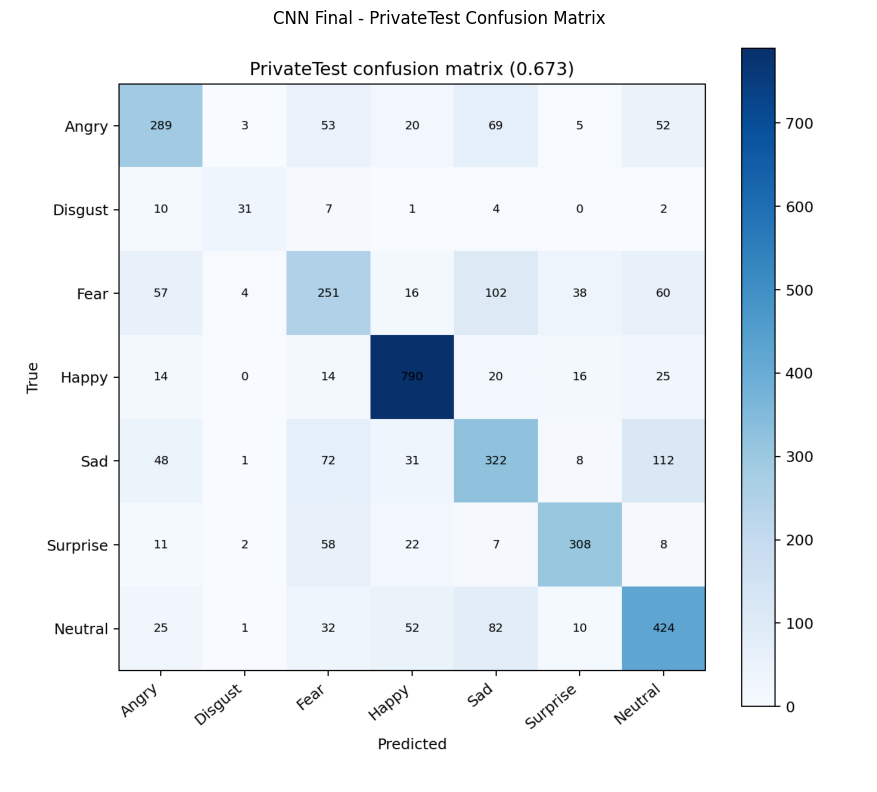


PrivateTest Accuracy: 0.6729 (67.29%)

Class         Precision     Recall         F1    Support
-------------------------------------------------------
Angry            0.6366     0.5886     0.6116      491.0
Disgust          0.7381     0.5636     0.6392       55.0
Fear             0.5154     0.4754     0.4946      528.0
Happy            0.8476     0.8987     0.8724      879.0
Sad              0.5314     0.5421     0.5367      594.0
Surprise         0.8000     0.7404     0.7690      416.0
Neutral          0.6208     0.6773     0.6478      626.0


In [21]:
# Hiển thị confusion matrix PrivateTest – CNN
cnn_cm_path = Path('results/runs/E4-03_best_seed42_s42/private_test_confusion_matrix.png')
if cnn_cm_path.exists():
    img = mpimg.imread(str(cnn_cm_path))
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title('CNN Final - PrivateTest Confusion Matrix')
    plt.tight_layout()
    plt.show()

# Hiển thị per-class metrics
pt_metrics_path = Path('results/runs/E4-03_best_seed42_s42/private_test_metrics.json')
if pt_metrics_path.exists():
    pt_metrics = json.loads(pt_metrics_path.read_text())
    print(f"\nPrivateTest Accuracy: {pt_metrics['accuracy']:.4f} ({pt_metrics['accuracy']*100:.2f}%)")
    cr = pt_metrics['classification_report']
    print(f"\n{'Class':<12} {'Precision':>10} {'Recall':>10} {'F1':>10} {'Support':>10}")
    print('-' * 55)
    for cls in ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']:
        if cls in cr:
            c = cr[cls]
            print(f"{cls:<12} {c['precision']:>10.4f} {c['recall']:>10.4f} {c['f1-score']:>10.4f} {c['support']:>10}")

### F2: Đánh giá ResNet18 pretrained (E4-01)

In [22]:
!python src/evaluate_pretrained.py \
    --run_dir /kaggle/working/results/runs/E4-resnet18_resnet18_s42 \
    --csv_path "$FER2013_CSV"

PrivateTest accuracy: 0.6743; saved metrics and confusion matrix under /kaggle/working/results/runs/E4-resnet18_resnet18_s42


ResNet18 PrivateTest Accuracy: 0.6743 (67.43%)


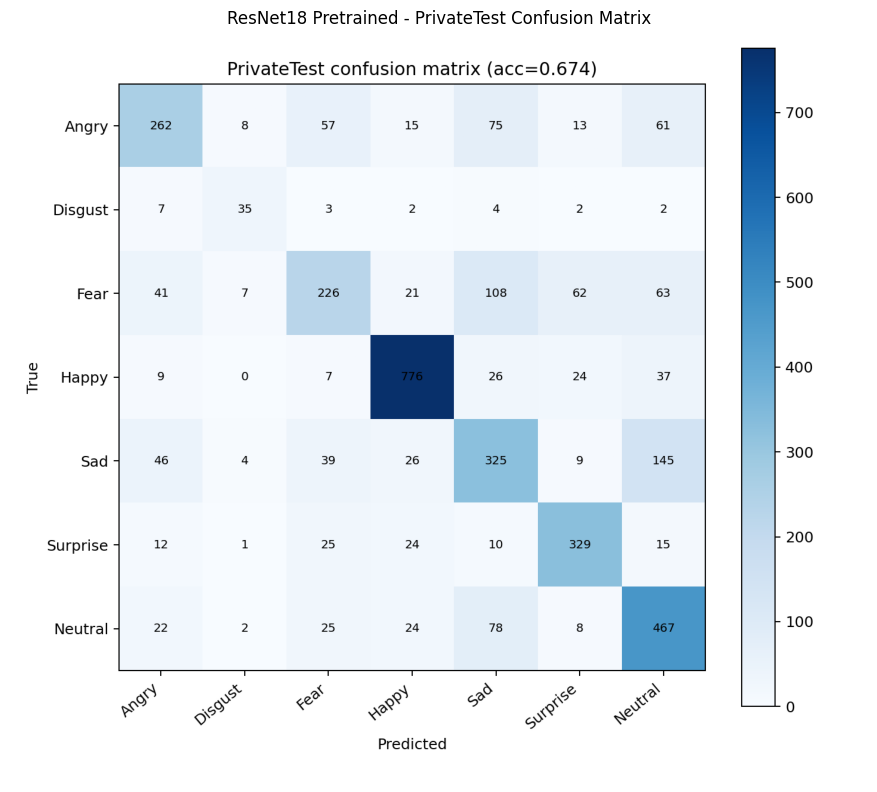

In [23]:
# Hiển thị kết quả PrivateTest – ResNet18
resnet_pt_path = Path('/kaggle/working/results/runs/E4-resnet18_resnet18_s42/private_test_metrics.json')
if resnet_pt_path.exists():
    resnet_pt = json.loads(resnet_pt_path.read_text())
    print(f"ResNet18 PrivateTest Accuracy: {resnet_pt['accuracy']:.4f} ({resnet_pt['accuracy']*100:.2f}%)")

    # Confusion matrix
    cm_path = resnet_pt_path.parent / 'private_test_confusion_matrix.png'
    if cm_path.exists():
        img = mpimg.imread(str(cm_path))
        fig, ax = plt.subplots(figsize=(9, 8))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title('ResNet18 Pretrained - PrivateTest Confusion Matrix')
        plt.tight_layout()
        plt.show()

### F3: Đánh giá VGG16 pretrained (E4-02)

In [24]:
!python src/evaluate_pretrained.py \
    --run_dir /kaggle/working/results/runs/E4-vgg16_vgg16_s42 \
    --csv_path "$FER2013_CSV"

PrivateTest accuracy: 0.6846; saved metrics and confusion matrix under /kaggle/working/results/runs/E4-vgg16_vgg16_s42


VGG16 PrivateTest Accuracy: 0.6846 (68.46%)


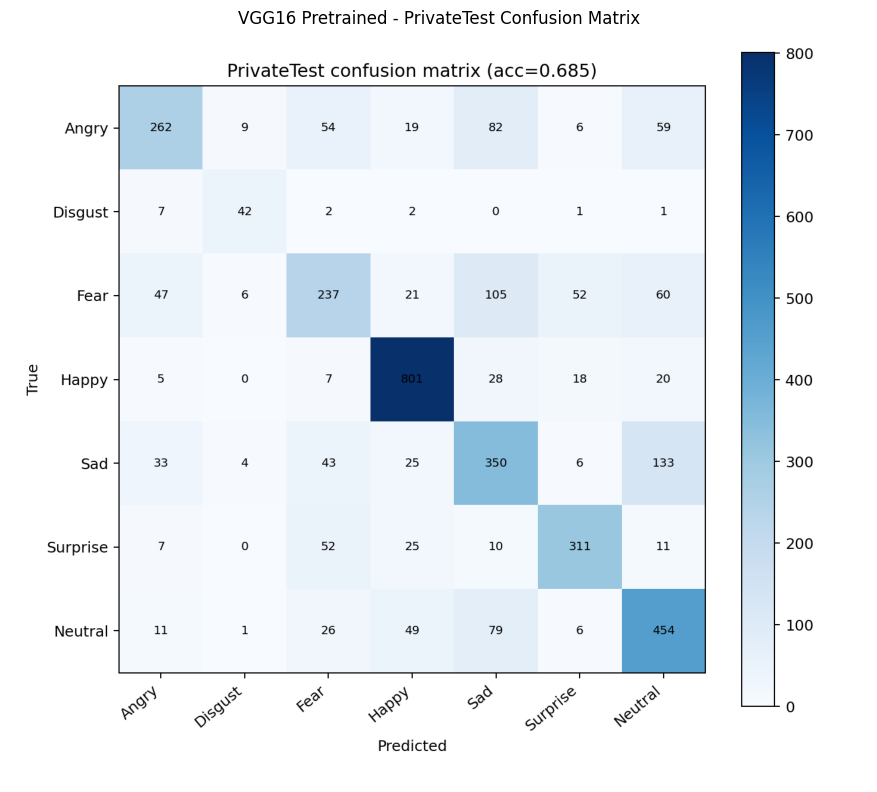

In [25]:
# Hiển thị kết quả PrivateTest – VGG16
vgg_pt_path = Path('/kaggle/working/results/runs/E4-vgg16_vgg16_s42/private_test_metrics.json')
if vgg_pt_path.exists():
    vgg_pt = json.loads(vgg_pt_path.read_text())
    print(f"VGG16 PrivateTest Accuracy: {vgg_pt['accuracy']:.4f} ({vgg_pt['accuracy']*100:.2f}%)")

    cm_path = vgg_pt_path.parent / 'private_test_confusion_matrix.png'
    if cm_path.exists():
        img = mpimg.imread(str(cm_path))
        fig, ax = plt.subplots(figsize=(9, 8))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title('VGG16 Pretrained - PrivateTest Confusion Matrix')
        plt.tight_layout()
        plt.show()

### F4: Đánh giá PrivateTest cho seed 43 và 44

In [26]:
# Seed 43
!python src/evaluate_final_cnn.py \
    --run_dir results/runs/E4-03_best_seed43_s43 \
    --csv_path "$FER2013_CSV"

# Seed 44
!python src/evaluate_final_cnn.py \
    --run_dir results/runs/E4-03_best_seed44_s44 \
    --csv_path "$FER2013_CSV"

PrivateTest accuracy: 0.6751; saved result under results/runs/E4-03_best_seed43_s43
PrivateTest accuracy: 0.6801; saved result under results/runs/E4-03_best_seed44_s44


---
## Phần G: Tổng hợp toàn bộ kết quả TV4

In [27]:
import json, statistics
from pathlib import Path
import pandas as pd

print("=" * 80)
print("           TỔNG HỢP KẾT QUẢ TV4 – LÊ THỊ THANH TUYỀN – 3123411332")
print("=" * 80)

# --- E4-01 / E4-02: Pretrained ---
print("\n--- E4: Transfer Learning (Pretrained) ---")
for label, run_dir in [('E4-01 ResNet18', Path('/kaggle/working/results/runs/E4-resnet18_resnet18_s42')),
                       ('E4-02 VGG16', Path('/kaggle/working/results/runs/E4-vgg16_vgg16_s42'))]:
    bm = run_dir / 'best_metrics.json'
    pt = run_dir / 'private_test_metrics.json'
    env = run_dir / 'env.json'
    if bm.exists():
        m = json.loads(bm.read_text())
        e = json.loads(env.read_text()) if env.exists() else {}
        p = json.loads(pt.read_text()) if pt.exists() else {}
        va_str = f"{m['val_acc']*100:.2f}%" if m['val_acc'] < 1 else f"{m['val_acc']:.2f}%"
        pt_str = f"{p['accuracy']*100:.2f}%" if p.get('accuracy') else 'N/A'
        print(f"  {label}: best_epoch={m['epoch']}, val_acc={va_str}, val_loss={m['val_loss']:.4f}, "
              f"test_acc={pt_str}, time={e.get('seconds','N/A')}s")

# --- E4-03: 3 seeds ---
print("\n--- E4-03: CNN tốt nhất qua 3 seed ---")
seed_results = []
for seed in [42, 43, 44]:
    run = Path(f'results/runs/E4-03_best_seed{seed}_s{seed}')
    hist_path = run / 'history.csv'
    pt_path = run / 'private_test_metrics.json'
    if hist_path.exists():
        import csv
        with hist_path.open(newline='', encoding='utf-8-sig') as f:
            rows = list(csv.DictReader(f))
        best = min(rows, key=lambda r: float(r['val_loss']))
        pt_acc = None
        if pt_path.exists():
            pt_data = json.loads(pt_path.read_text())
            pt_acc = pt_data['accuracy']
        result = {
            'seed': seed,
            'best_epoch': int(float(best['epoch'])),
            'val_acc': float(best['val_acc']),
            'val_loss': float(best['val_loss']),
            'test_acc': pt_acc
        }
        seed_results.append(result)
        pt_str = f"{pt_acc*100:.2f}%" if pt_acc else 'N/A'
        va_str = f"{result['val_acc']*100:.2f}%" if result['val_acc'] < 1 else f"{result['val_acc']:.2f}%"
        print(f"  Seed {seed}: best_epoch={result['best_epoch']}, val_acc={va_str}, "
              f"val_loss={result['val_loss']:.4f}, test_acc={pt_str}")

if len(seed_results) >= 2:
    val_accs = [r['val_acc'] for r in seed_results]
    val_losses = [r['val_loss'] for r in seed_results]
    test_accs = [r['test_acc'] for r in seed_results if r['test_acc'] is not None]
    
    mean_va = statistics.mean(val_accs)
    std_va = statistics.stdev(val_accs) if len(val_accs) >= 2 else 0
    mean_vl = statistics.mean(val_losses)
    std_vl = statistics.stdev(val_losses) if len(val_losses) >= 2 else 0
    
    if mean_va < 1:  # fraction
        print(f"\n  Mean ± Std Val Acc:  {mean_va*100:.2f}% ± {std_va*100:.2f}%")
    else:
        print(f"\n  Mean ± Std Val Acc:  {mean_va:.2f}% ± {std_va:.2f}%")
    print(f"  Mean ± Std Val Loss: {mean_vl:.4f} ± {std_vl:.4f}")
    if test_accs:
        mean_ta = statistics.mean(test_accs)
        std_ta = statistics.stdev(test_accs) if len(test_accs) >= 2 else 0
        print(f"  Mean ± Std Test Acc: {mean_ta*100:.2f}% ± {std_ta*100:.2f}%")

print("\n" + "=" * 80)

           TỔNG HỢP KẾT QUẢ TV4 – LÊ THỊ THANH TUYỀN – 3123411332

--- E4: Transfer Learning (Pretrained) ---
  E4-01 ResNet18: best_epoch=7, val_acc=65.90%, val_loss=0.9412, test_acc=67.43%, time=187.27427101135254s
  E4-02 VGG16: best_epoch=11, val_acc=68.26%, val_loss=0.9233, test_acc=68.46%, time=1317.5890471935272s

--- E4-03: CNN tốt nhất qua 3 seed ---
  Seed 42: best_epoch=43, val_acc=66.40%, val_loss=0.9394, test_acc=67.29%
  Seed 43: best_epoch=57, val_acc=66.82%, val_loss=0.9314, test_acc=67.51%
  Seed 44: best_epoch=43, val_acc=66.45%, val_loss=0.9288, test_acc=68.01%

  Mean ± Std Val Acc:  66.56% ± 0.23%
  Mean ± Std Val Loss: 0.9332 ± 0.0055
  Mean ± Std Test Acc: 67.60% ± 0.37%



---
## Phần H: Cập nhật nhật ký thí nghiệm TV4

In [28]:
import csv, json, datetime
from pathlib import Path

log_rows = []
now = datetime.datetime.now().strftime('%Y-%m-%d %H:%M')

# E4-01 ResNet18
run = Path('/kaggle/working/results/runs/E4-resnet18_resnet18_s42')
bm = json.loads((run / 'best_metrics.json').read_text()) if (run / 'best_metrics.json').exists() else {}
env = json.loads((run / 'env.json').read_text()) if (run / 'env.json').exists() else {}
pt = json.loads((run / 'private_test_metrics.json').read_text()) if (run / 'private_test_metrics.json').exists() else {}
log_rows.append({
    'ExpID': 'E4-01', 'date_time': now, 'runner': 'TV4',
    'purpose': 'ResNet18 ImageNet pretrained fine-tune',
    'change_vs_baseline': 'ResNet18 ImageNet pretrained; resize 96; RGB replicate; ImageNet normalization',
    'seed': 42, 'best_epoch': bm.get('epoch',''), 'val_loss': f"{bm.get('val_loss',0):.4f}" if bm else '',
    'val_acc': f"{bm.get('val_acc',0):.4f}" if bm else '', 'test_acc': f"{pt.get('accuracy',0):.4f}" if pt else '',
    'runtime_minutes': f"{env.get('seconds',0)/60:.1f}" if env.get('seconds') else '',
    'run_dir': str(run), 'status': 'DONE' if bm else 'ERROR', 'notes': ''
})

# E4-02 VGG16
run = Path('/kaggle/working/results/runs/E4-vgg16_vgg16_s42')
bm = json.loads((run / 'best_metrics.json').read_text()) if (run / 'best_metrics.json').exists() else {}
env = json.loads((run / 'env.json').read_text()) if (run / 'env.json').exists() else {}
pt = json.loads((run / 'private_test_metrics.json').read_text()) if (run / 'private_test_metrics.json').exists() else {}
log_rows.append({
    'ExpID': 'E4-02', 'date_time': now, 'runner': 'TV4',
    'purpose': 'VGG16 ImageNet pretrained fine-tune',
    'change_vs_baseline': 'VGG16 ImageNet pretrained; resize 96; RGB replicate; ImageNet normalization',
    'seed': 42, 'best_epoch': bm.get('epoch',''), 'val_loss': f"{bm.get('val_loss',0):.4f}" if bm else '',
    'val_acc': f"{bm.get('val_acc',0):.4f}" if bm else '', 'test_acc': f"{pt.get('accuracy',0):.4f}" if pt else '',
    'runtime_minutes': f"{env.get('seconds',0)/60:.1f}" if env.get('seconds') else '',
    'run_dir': str(run), 'status': 'DONE' if bm else 'ERROR', 'notes': ''
})

# E4-03 seeds
for seed in [42, 43, 44]:
    run = Path(f'results/runs/E4-03_best_seed{seed}_s{seed}')
    hist_path = run / 'history.csv'
    pt_path = run / 'private_test_metrics.json'
    env_path = run / 'env.json'
    best_epoch = val_loss = val_acc = test_acc = runtime = ''
    status = 'NOT_RUN'
    if hist_path.exists():
        with hist_path.open(newline='', encoding='utf-8-sig') as f:
            rows = list(csv.DictReader(f))
        if rows:
            best = min(rows, key=lambda r: float(r['val_loss']))
            best_epoch = int(float(best['epoch']))
            val_loss = f"{float(best['val_loss']):.4f}"
            val_acc = f"{float(best['val_acc']):.4f}"
            status = 'DONE'
    if pt_path.exists():
        pt_data = json.loads(pt_path.read_text())
        test_acc = f"{pt_data['accuracy']:.4f}"
    if env_path.exists():
        env_data = json.loads(env_path.read_text())
        if 'seconds' in env_data:
            runtime = f"{env_data['seconds']/60:.1f}"
        elif 'end_time' in env_data and 'start_time' in env_data:
            runtime = 'see env.json'
    log_rows.append({
        'ExpID': 'E4-03', 'date_time': now, 'runner': 'TV4',
        'purpose': f'Final selected model seed {seed}',
        'change_vs_baseline': 'Final selected model; same config across seeds (E2-04: Adam lr=1e-4)',
        'seed': seed, 'best_epoch': best_epoch, 'val_loss': val_loss,
        'val_acc': val_acc, 'test_acc': test_acc,
        'runtime_minutes': runtime, 'run_dir': str(run),
        'status': status, 'notes': ''
    })

# Ghi file nhật ký
log_path = Path('results/experiment_log_TV4.csv')
fieldnames = ['ExpID','date_time','runner','purpose','change_vs_baseline','seed','best_epoch','val_loss','val_acc','test_acc','runtime_minutes','run_dir','status','notes']
with log_path.open('w', newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fieldnames=fieldnames)
    w.writeheader()
    w.writerows(log_rows)

print(f"Đã cập nhật nhật ký: {log_path}")
print(pd.read_csv(log_path).to_string(index=False))

Đã cập nhật nhật ký: results/experiment_log_TV4.csv
ExpID        date_time runner                                purpose                                                             change_vs_baseline  seed  best_epoch  val_loss  val_acc  test_acc runtime_minutes                                               run_dir status  notes
E4-01 2026-11-23 21:56    TV4 ResNet18 ImageNet pretrained fine-tune ResNet18 ImageNet pretrained; resize 96; RGB replicate; ImageNet normalization    42           7    0.9412   0.6590    0.6743             3.1 /kaggle/working/results/runs/E4-resnet18_resnet18_s42   DONE    NaN
E4-02 2026-11-23 21:56    TV4    VGG16 ImageNet pretrained fine-tune    VGG16 ImageNet pretrained; resize 96; RGB replicate; ImageNet normalization    42          11    0.9233   0.6826    0.6846            22.0       /kaggle/working/results/runs/E4-vgg16_vgg16_s42   DONE    NaN
E4-03 2026-11-23 21:56    TV4           Final selected model seed 42           Final selected model; same confi

---
## Phần I: Learning curves cho các run TV4

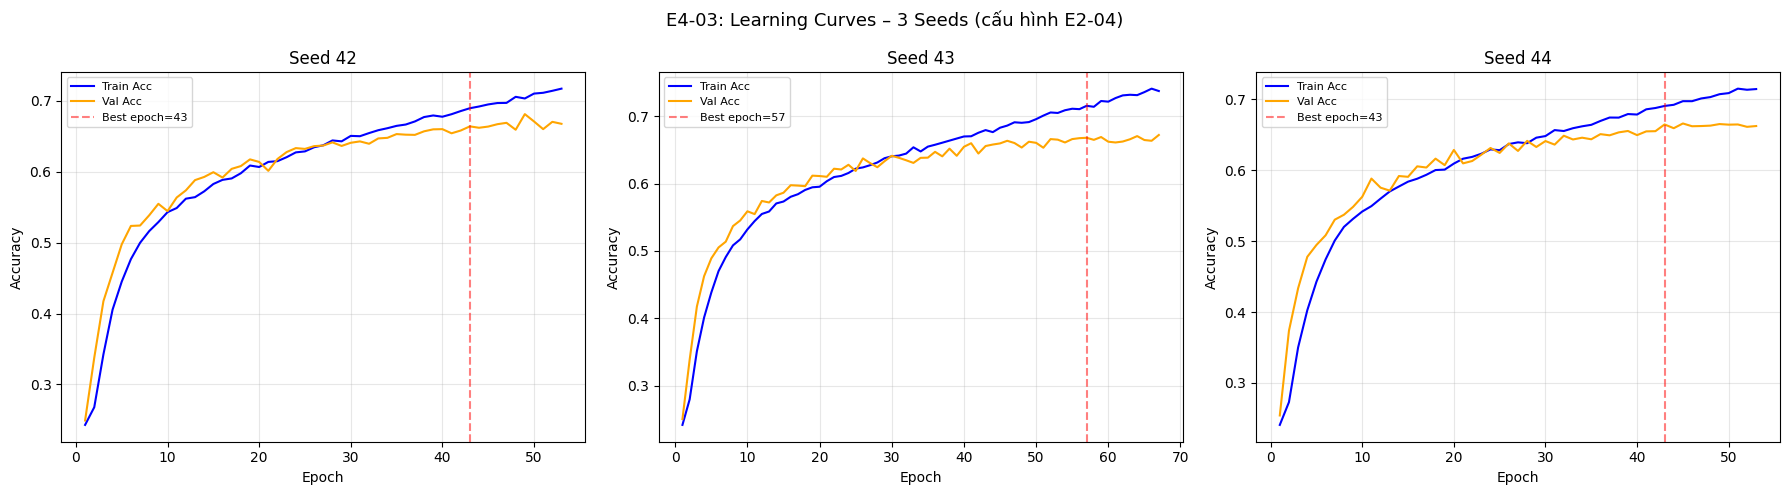

Đã lưu: results/figures/E4-03_learning_curves_3seeds.png


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ learning curves cho 3 seeds
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, seed in enumerate([42, 43, 44]):
    hist_path = Path(f'results/runs/E4-03_best_seed{seed}_s{seed}/history.csv')
    if hist_path.exists():
        df = pd.read_csv(hist_path)
        ax = axes[idx]
        ax.plot(df['epoch'], df['train_acc'], label='Train Acc', color='blue')
        ax.plot(df['epoch'], df['val_acc'], label='Val Acc', color='orange')
        best_epoch = df.loc[df['val_loss'].idxmin(), 'epoch']
        ax.axvline(x=best_epoch, color='red', linestyle='--', alpha=0.5, label=f'Best epoch={int(best_epoch)}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Accuracy')
        ax.set_title(f'Seed {seed}')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

fig.suptitle('E4-03: Learning Curves – 3 Seeds (cấu hình E2-04)', fontsize=13)
plt.tight_layout()
plt.savefig('results/figures/E4-03_learning_curves_3seeds.png', dpi=150, bbox_inches='tight')
plt.show()
print("Đã lưu: results/figures/E4-03_learning_curves_3seeds.png")

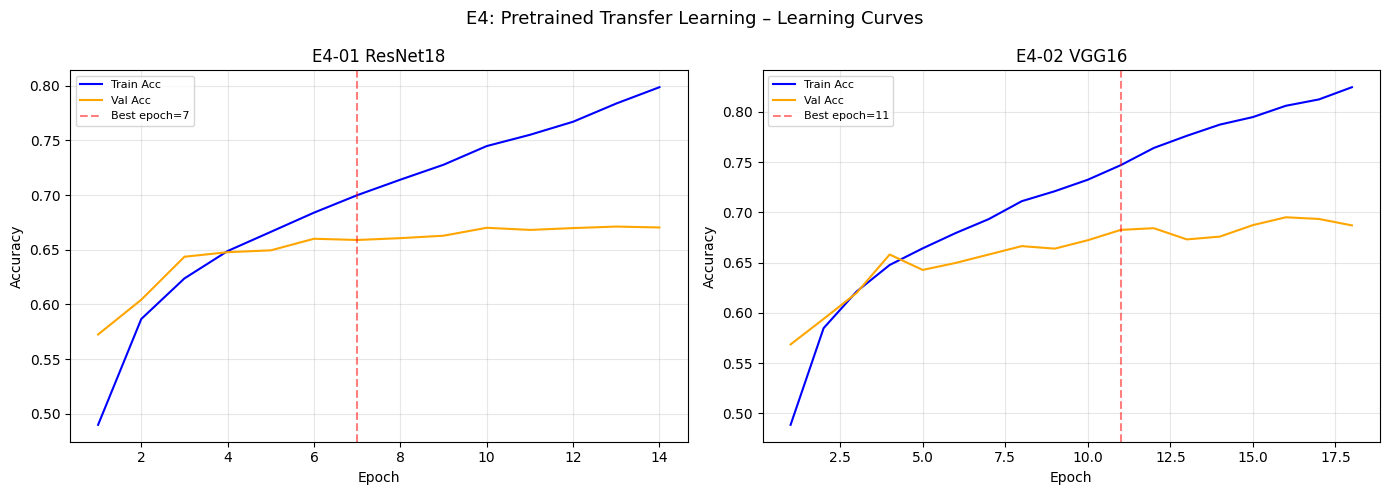

Đã lưu: results/figures/E4_pretrained_learning_curves.png


In [30]:
# Vẽ learning curves cho E4-01 (ResNet18) và E4-02 (VGG16)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, (label, run_dir) in enumerate([('E4-01 ResNet18', Path('/kaggle/working/results/runs/E4-resnet18_resnet18_s42')),
                                         ('E4-02 VGG16', Path('/kaggle/working/results/runs/E4-vgg16_vgg16_s42'))]):
    hist_path = run_dir / 'history.csv'
    if hist_path.exists():
        df = pd.read_csv(hist_path)
        ax = axes[idx]
        ax.plot(df['epoch'], df['train_acc'], label='Train Acc', color='blue')
        ax.plot(df['epoch'], df['val_acc'], label='Val Acc', color='orange')
        best_epoch = df.loc[df['val_loss'].idxmin(), 'epoch']
        ax.axvline(x=best_epoch, color='red', linestyle='--', alpha=0.5, label=f'Best epoch={int(best_epoch)}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Accuracy')
        ax.set_title(label)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

fig.suptitle('E4: Pretrained Transfer Learning – Learning Curves', fontsize=13)
plt.tight_layout()
plt.savefig('results/figures/E4_pretrained_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Đã lưu: results/figures/E4_pretrained_learning_curves.png")

---
## Phần J: Copy kết quả về repo để commit

In [31]:
import shutil
from pathlib import Path

# Copy các run E4 pretrained từ /kaggle/working vào results/runs/ của repo
for run_name in ['E4-resnet18_resnet18_s42', 'E4-vgg16_vgg16_s42']:
    src = Path(f'/kaggle/working/results/runs/{run_name}')
    dst = Path(f'results/runs/{run_name}')
    if src.exists():
        dst.mkdir(parents=True, exist_ok=True)
        for f in src.iterdir():
            if f.name != 'best.pt':  # Không copy checkpoint lớn vào git
                shutil.copy2(f, dst / f.name)
                print(f"  Copied: {run_name}/{f.name}")

print("\n=== Liệt kê tất cả run dirs ===")
runs_dir = Path('results/runs')
for d in sorted(runs_dir.iterdir()):
    if d.is_dir() and d.name.startswith('E4'):
        files = [f.name for f in d.iterdir()]
        print(f"  {d.name}/: {files}")

  Copied: E4-resnet18_resnet18_s42/private_test_metrics.json
  Copied: E4-resnet18_resnet18_s42/config.json
  Copied: E4-resnet18_resnet18_s42/env.json
  Copied: E4-resnet18_resnet18_s42/history.csv
  Copied: E4-resnet18_resnet18_s42/best_metrics.json
  Copied: E4-resnet18_resnet18_s42/private_test_confusion_matrix.png
  Copied: E4-vgg16_vgg16_s42/private_test_metrics.json
  Copied: E4-vgg16_vgg16_s42/config.json
  Copied: E4-vgg16_vgg16_s42/env.json
  Copied: E4-vgg16_vgg16_s42/history.csv
  Copied: E4-vgg16_vgg16_s42/best_metrics.json
  Copied: E4-vgg16_vgg16_s42/private_test_confusion_matrix.png

=== Liệt kê tất cả run dirs ===
  E4-03_best_seed42_s42/: ['private_test_metrics.json', 'config.json', 'learning_curves.png', 'env.json', 'history.csv', 'train.log', 'best.pt', 'private_test_confusion_matrix.png']
  E4-03_best_seed43_s43/: ['private_test_metrics.json', 'config.json', 'learning_curves.png', 'env.json', 'history.csv', 'train.log', 'best.pt', 'private_test_confusion_matrix.png

## Phần K: Liệt kê toàn bộ output để lưu minh chứng

Dùng **Save Version → Save & Run All** trên Kaggle để lưu toàn bộ notebook output.  
Chụp screenshots các ô kết quả quan trọng để lưu vào `evidence/ThanhVien4/`.

In [32]:
import os
from pathlib import Path

print("=== TOÀN BỘ FILE KẾT QUẢ ĐÃ TẠO ===")
print("\n--- results/figures/ ---")
fig_dir = Path('results/figures')
if fig_dir.exists():
    for f in sorted(fig_dir.iterdir()):
        if f.is_file():
            print(f"  {f.name}  ({f.stat().st_size / 1024:.0f} KB)")

print("\n--- results/runs/ (E4 runs) ---")
runs_dir = Path('results/runs')
for d in sorted(runs_dir.iterdir()):
    if d.is_dir() and d.name.startswith('E4'):
        total_size = sum(f.stat().st_size for f in d.iterdir() if f.is_file())
        files = sorted([f.name for f in d.iterdir() if f.is_file()])
        print(f"  {d.name}/ ({total_size/1024:.0f} KB): {files}")

print("\n--- results/ (CSV summaries) ---")
for f in sorted(Path('results').iterdir()):
    if f.is_file() and f.suffix == '.csv':
        print(f"  {f.name}")

print("\n=== HOÀN TẤT NOTEBOOK TV4 ===")

=== TOÀN BỘ FILE KẾT QUẢ ĐÃ TẠO ===

--- results/figures/ ---
  .gitkeep  (0 KB)
  E4-03_best_seed42_s42_activation_maximization.png  (61 KB)
  E4-03_best_seed42_s42_first_kernels.png  (43 KB)
  E4-03_best_seed42_s42_last_feature_maps.png  (239 KB)
  E4-03_learning_curves_3seeds.png  (118 KB)
  E4_pretrained_learning_curves.png  (97 KB)
  compare_E1_val.png  (238 KB)
  compare_E2_val.png  (207 KB)
  compare_E3_val.png  (205 KB)
  eda_augmentation_grid.png  (135 KB)
  eda_class_distribution.png  (93 KB)
  eda_samples_grid.png  (206 KB)
  gradcam_final.png  (171 KB)

--- results/runs/ (E4 runs) ---
  E4-03_best_seed42_s42/ (44489 KB): ['best.pt', 'config.json', 'env.json', 'history.csv', 'learning_curves.png', 'private_test_confusion_matrix.png', 'private_test_metrics.json', 'train.log']
  E4-03_best_seed43_s43/ (44494 KB): ['best.pt', 'config.json', 'env.json', 'history.csv', 'learning_curves.png', 'private_test_confusion_matrix.png', 'private_test_metrics.json', 'train.log']
  E4-03_be